# CNW-Grass gas exchange, 2: change a parameter

**What you will learn:** list the parameters with their units, change one, choose another model of the stomata, and
change the leaves' nitrogen and the air's CO₂.

**You need:** tutorial 1. **Run time:** about 30 seconds.

Each run here computes a single hour, at noon (`hours=1, start_hour=12`): about 2 seconds each.

## 1. The parameters

A **parameter** is a number describing the plants (how much photosynthetic enzyme a gram of nitrogen makes, ...);
a **setting** is a choice for the whole model (which model of the stomata, ...). Both stay fixed during a simulation.
`parameters()` lists them with their value, unit and description; `parameters(main_only=True)` keeps the main ones.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd

from openalea.cnwgrass.metafspm.simulation import parameters, simulate

parameters(main_only=True)[["name", "value", "unit", "description"]]

,name,value,unit,description
0,stomatal_model,BWB,,"The stomatal conductance: 'BWB' (Ball, Woodrow..."
1,Vc_max25_nitrogen_slope,84.965,µmol g-1 s-1,Vc_max25's increase with Na
2,Jmax25_nitrogen_slope,117.6,µmol g-1 s-1,Jmax25's increase with Na
3,THETA,0.72,adim,The curvature of J's light response (θ)
4,BWB_slope_factor,14.7,adim,δ1 of the BWB slope m = δ1 Na^δ2
5,minimum_stomatal_conductance,0.05,mol m-2 s-1,"gs in the dark (g0, GSMIN)"
6,stomatal_slope,5.7,adim,"The slope m' of the Leuning, Tuzet and hydraul..."
7,stem_efficiency,0.78,adim,The relative Ag of a non-lamina element (stems...
8,wind_attenuation,2.5,adim,The wind's attenuation coefficient in the cano...
9,corrections,recommended,,The legacy's behaviours corrected: 'recommende...


In plain words:

| parameter | what it controls |
|---|---|
| `stomatal_model` | the model of the stomata (section 3) |
| `Vc_max25_nitrogen_slope` | the RuBisCO capacity (the CO₂-fixing enzyme) per g of nitrogen |
| `Jmax25_nitrogen_slope` | the electron transport capacity (the light-driven part) per g of nitrogen |
| `THETA` | how sharply the light response levels off (0: gradually, 1: abruptly) |
| `BWB_slope_factor` | how much the stomata open with photosynthesis (the BWB model) |
| `minimum_stomatal_conductance` | the stomata's opening in the dark |
| `stomatal_slope` | how much the stomata open with photosynthesis (the Leuning and Tuzet models) |
| `stem_efficiency` | a stem's or sheath's assimilation relative to a blade's |
| `wind_attenuation` | how fast the wind weakens down the canopy |
| `corrections` | the corrections of the original code's errors (section 6) |

`parameters()` (without `main_only`) lists all of them, with their references.

## 2. Change one parameter

`simulate` takes the parameters to change as a dictionary, `{name: value}`. Here 20 % less RuBisCO per g of
nitrogen, then 20 % less electron transport:

In [2]:
columns = ["net_assimilation", "transpiration", "stomatal_conductance", "surface_temperature"]
defaults = parameters().set_index("name")["value"]
reference = simulate(hours=1, start_hour=12)
less_rubisco = simulate({"Vc_max25_nitrogen_slope": 0.8 * defaults["Vc_max25_nitrogen_slope"]}, hours=1,
                        start_hour=12)
less_transport = simulate({"Jmax25_nitrogen_slope": 0.8 * defaults["Jmax25_nitrogen_slope"]}, hours=1,
                          start_hour=12)
pd.DataFrame({"default": reference.summary.iloc[0][columns],
              "20 % less RuBisCO": less_rubisco.summary.iloc[0][columns],
              "20 % less electron transport": less_transport.summary.iloc[0][columns]}).round(3)

,default,20 % less RuBisCO,20 % less electron transport
net_assimilation,10.033,10.033,8.926
transpiration,2.003,2.003,1.974
stomatal_conductance,0.310,0.310,0.281
surface_temperature,24.471,24.471,24.685


Less RuBisCO changes nothing; less electron transport lowers the CO₂ fixed. A leaf fixes CO₂ at the lower of the
rate its RuBisCO allows and the rate its electron transport allows: with the default parameters, the electron
transport is always the lower one, and RuBisCO has capacity to spare (tutorial 3 explores this). With the default
stomatal model the stomata open with photosynthesis: they close a little too.

## 3. The stomatal model

The stomata open with photosynthesis, and close when the air is dry or the plant short of water. Four models are
available, as the setting `stomatal_model`:

| model | the stomata respond to |
|---|---|
| `BWB` (Ball, Woodrow and Berry; the default) | photosynthesis, the air's humidity, the CO₂ at the leaf surface |
| `Leuning` | photosynthesis, the air's dryness (vapour pressure deficit), the CO₂ |
| `Tuzet` | photosynthesis, the leaf's water potential (how short of water it is), the CO₂ |
| `hydraulics` | Leuning's and Tuzet's together |

In [3]:
rows = {}
for model in ("BWB", "Leuning", "Tuzet", "hydraulics"):
    rows[model] = simulate({"stomatal_model": model}, hours=1, start_hour=12).summary.iloc[0][columns]
pd.DataFrame(rows).T.round(3)

,net_assimilation,transpiration,stomatal_conductance,surface_temperature
BWB,10.033,2.003,0.310,24.471
Leuning,10.551,2.119,0.480,23.614
Tuzet,10.576,2.126,0.494,23.564
hydraulics,10.550,2.119,0.480,23.614


With a well-watered plant (the default leaf water potential, −0.1 MPa) and this moderately humid air, the three
other models open the stomata more than BWB; the assimilation gains a little, the transpiration too, though much
less than the conductance: a canopy's transpiration depends more on the energy it absorbs and on the air than on its
stomata, as long as they are open. Tuzet and hydraulics read the leaf water potential, which a water model computes:
tutorial 6 changes it.

## 4. Not a parameter: the leaves' nitrogen

The nitrogen of each element (g m⁻²) is an **input**: in a complete plant model, a nitrogen model computes it. Here
`simulate` gives every element the same value, `surfacic_nitrogen=` (2 by default):

nitrogen (g m-2)
0.5     4.061
1.0     6.666
1.5     8.555
2.0    10.033
2.5    11.258
3.0    12.327
Name: net_assimilation, dtype: float64

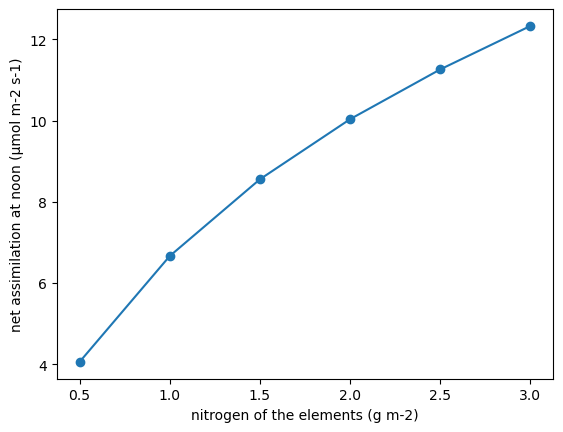

In [4]:
nitrogen = [0.5, 1., 1.5, 2., 2.5, 3.]
assimilation = [simulate(hours=1, start_hour=12, surfacic_nitrogen=value).summary.iloc[0]["net_assimilation"]
                for value in nitrogen]
plt.plot(nitrogen, assimilation, "o-")
plt.xlabel("nitrogen of the elements (g m-2)"); plt.ylabel("net assimilation at noon (µmol m-2 s-1)")
pd.Series(assimilation, index=nitrogen, name="net_assimilation").rename_axis("nitrogen (g m-2)").round(3)

More nitrogen, more photosynthetic capacity: the stand fixes more CO₂, with diminishing returns as the light, not
the enzymes, becomes the limit.

## 5. The weather: CO₂

The weather is given the same way (`air_temperature=`, `relative_humidity=`, `ambient_CO2=`, `wind_speed=`,
`PARi=`): a number, or one value per hour (tutorial 5). The air's CO₂ from pre-industrial (280 ppm) to a high future
level (800 ppm):

In [5]:
rows = {}
for CO2 in (280., 410., 800.):
    row = simulate(hours=1, start_hour=12, ambient_CO2=CO2).summary.iloc[0]
    rows[f"{CO2:.0f} ppm"] = {**row[columns], "water use efficiency": row["net_assimilation"] / row["transpiration"]}
pd.DataFrame(rows).T.round(3)

,net_assimilation,transpiration,stomatal_conductance,surface_temperature,water use efficiency
280 ppm,8.393,2.056,0.371,24.080,4.082
410 ppm,10.033,2.003,0.310,24.471,5.008
800 ppm,12.060,1.871,0.208,25.449,6.446


More CO₂: more assimilation, and the stomata close (the BWB model divides by the CO₂ at the leaf surface), so the
leaves lose less water and warm up. The CO₂ fixed per unit of water lost (here in µmol of CO₂ per mmol of water)
rises steeply: one of the main expected effects of rising CO₂ on crops.

## 6. The corrections

The model is a port of CNW-Grass's original code. Three errors found in the original are corrected by default
(`corrections="recommended"`); `corrections=()` gives the original's results exactly. One concerns the CO₂
compensation point of the Leuning, Tuzet and hydraulics models, which the original computes in the wrong unit:

In [6]:
rows = {}
for name, corrections in (("corrected (default)", "recommended"), ("original", ())):
    rows[name] = simulate({"stomatal_model": "Leuning", "corrections": corrections}, hours=1,
                          start_hour=12).summary.iloc[0][columns]
pd.DataFrame(rows).T.round(3)

,net_assimilation,transpiration,stomatal_conductance,surface_temperature
corrected (default),10.551,2.119,0.480,23.614
original,10.486,2.103,0.448,23.733


With the original's unit the stomata open less. The developer tutorials list the three corrections.

## Try it yourself

1. Change `THETA` from 0.72 to 0.9. Which leaves gain most, the sunlit or the shaded ones? (Compare
   `elements()`.)
2. Compare the four stomatal models in dry air (`relative_humidity=0.3`). Which one closes the stomata most?
3. At which air temperature does the stand fix the most CO₂ at noon? (Try 5 to 35 °C.)

**Next:** `03_combine_parameters.ipynb`.